In [1]:

# ---------- CONFIG (edit these) ----------
CSV_PATH   = r"/mnt/c/Users/Ishara/Documents/MPhil/Dataset/Final dataset/without timing/full sim results.csv"   # <- change to your file
TARGET_COL = "isUnderAttack"

In [2]:
# ---------- Imports ----------
import warnings, sys
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

from packaging import version
import sklearn
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, train_test_split, cross_val_score
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

import optuna
from optuna.samplers import TPESampler

# ---------- Reproducibility ----------
SEED = 42
rng  = np.random.RandomState(SEED)

# ---------- Load data ----------
df = pd.read_csv(CSV_PATH)
X  = df.drop(columns=[TARGET_COL])
y  = df[TARGET_COL]

print(f"[INFO] Loaded {CSV_PATH}: {df.shape[0]} rows, {df.shape[1]} cols (features={X.shape[1]}, target='{TARGET_COL}')")

[INFO] Loaded /mnt/c/Users/Ishara/Documents/MPhil/Dataset/Final dataset/without timing/full sim results.csv: 58025 rows, 11 cols (features=10, target='isUnderAttack')


In [3]:
# ---------- Train/Test split (75/25 stratified) ----------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=SEED, stratify=y
)
print(f"[INFO] Split: TRAIN={X_train.shape[0]}  TEST={X_test.shape[0]}")

# ---------- CV splitter ----------
CV10 = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)

# ---------- Supported criteria based on sklearn version ----------
if version.parse(sklearn.__version__) >= version.parse("1.1"):
    CRITERIA = ["gini", "entropy", "log_loss"]
else:
    CRITERIA = ["gini", "entropy"]
    print("[WARN] scikit-learn < 1.1 detected -> 'log_loss' criterion disabled.")


[INFO] Split: TRAIN=43518  TEST=14507


In [4]:
# ---------- Optuna objective ----------
def objective(trial: optuna.Trial) -> float:
    # Choose how to specify max_features
    max_feat_choice = trial.suggest_categorical("max_features_choice", ["sqrt", "log2", "float"])
    if max_feat_choice == "float":
        max_features = trial.suggest_float("max_features_frac", 0.3, 1.0) 
    else:
        max_features = max_feat_choice

    params = dict(
        criterion        = trial.suggest_categorical("criterion", CRITERIA),
        n_estimators     = trial.suggest_int("n_estimators", 10, 1000, step=50),
        max_depth        = trial.suggest_int("max_depth", 5, 60),
        min_samples_split= trial.suggest_int("min_samples_split", 2, 20),
        min_samples_leaf = trial.suggest_int("min_samples_leaf", 1, 10),
        bootstrap        = trial.suggest_categorical("bootstrap", [True, False]),
        ccp_alpha        = trial.suggest_float("ccp_alpha", 0.0, 0.01, step=0.001),
        max_features     = max_features,
        class_weight     = "balanced",
        random_state     = SEED,
        n_jobs           = -1,
    )

    clf = RandomForestClassifier(**params)

    # Avoid nested parallelism: keep CV single-threaded (RF already parallel)
    scores = cross_val_score(
        clf, X_train, y_train,
        cv=CV10,
        scoring="f1_macro",
        n_jobs=1,
        error_score="raise"
    )
    return float(np.mean(scores))


In [5]:
# ---------- Run Optuna study ----------
N_TRIALS = 60  # increase if you want more thorough search
study = optuna.create_study(
    direction="maximize",
    sampler=TPESampler(seed=SEED)
)
study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=False)

print("\n===== Optuna best trial =====")
print("Best F1-macro (CV10):", f"{study.best_value:.6f}")
print("Best params:")
for k, v in study.best_trial.params.items():
    print(f"  {k}: {v}")



[I 2025-10-18 12:20:26,143] A new study created in memory with name: no-name-1f18c05b-dd37-476e-b3b9-7d5954426da0
[I 2025-10-18 12:20:29,505] Trial 0 finished with value: 0.89422561225776 and parameters: {'max_features_choice': 'log2', 'criterion': 'gini', 'n_estimators': 60, 'max_depth': 53, 'min_samples_split': 13, 'min_samples_leaf': 8, 'bootstrap': False, 'ccp_alpha': 0.009000000000000001}. Best is trial 0 with value: 0.89422561225776.
[I 2025-10-18 12:20:42,321] Trial 1 finished with value: 0.918317089492121 and parameters: {'max_features_choice': 'sqrt', 'criterion': 'entropy', 'n_estimators': 260, 'max_depth': 39, 'min_samples_split': 4, 'min_samples_leaf': 3, 'bootstrap': False, 'ccp_alpha': 0.008}. Best is trial 1 with value: 0.918317089492121.
[I 2025-10-18 12:21:16,730] Trial 2 finished with value: 0.9167498011253938 and parameters: {'max_features_choice': 'float', 'max_features_frac': 0.3325152889039984, 'criterion': 'gini', 'n_estimators': 910, 'max_depth': 59, 'min_sample


===== Optuna best trial =====
Best F1-macro (CV10): 0.986310
Best params:
  max_features_choice: float
  max_features_frac: 0.8430774202347376
  criterion: log_loss
  n_estimators: 410
  max_depth: 29
  min_samples_split: 10
  min_samples_leaf: 7
  bootstrap: True
  ccp_alpha: 0.0


In [6]:
# ---------- Rebuild best model ----------
bp = study.best_trial.params.copy()

# Resolve max_features actual value
if bp["max_features_choice"] == "float":
    max_features = bp["max_features_frac"]
else:
    max_features = bp["max_features_choice"]

final_params = dict(
    criterion        = bp["criterion"],
    n_estimators     = bp["n_estimators"],
    max_depth        = bp["max_depth"],
    min_samples_split= bp["min_samples_split"],
    min_samples_leaf = bp["min_samples_leaf"],
    bootstrap        = bp["bootstrap"],
    ccp_alpha        = bp["ccp_alpha"],
    max_features     = max_features,
    class_weight     = "balanced",
    random_state     = SEED,
    n_jobs           = -1,
)

best_rf = RandomForestClassifier(**final_params)

# ---------- 10-fold CV on TRAIN for the tuned model ----------
acc_folds, f1m_folds = [], []
for fold, (tr_idx, va_idx) in enumerate(CV10.split(X_train, y_train), start=1):
    Xt, Xv = X_train.iloc[tr_idx], X_train.iloc[va_idx]
    yt, yv = y_train.iloc[tr_idx], y_train.iloc[va_idx]
    best_rf.fit(Xt, yt)
    yv_pred = best_rf.predict(Xv)
    acc_folds.append(accuracy_score(yv, yv_pred))
    f1m_folds.append(f1_score(yv, yv_pred, average="macro"))

cv_acc_mean, cv_acc_std = float(np.mean(acc_folds)), float(np.std(acc_folds, ddof=0))
cv_f1m_mean, cv_f1m_std = float(np.mean(f1m_folds)), float(np.std(f1m_folds, ddof=0))

print("\n===== Tuned RF | 10-fold CV (TRAIN) =====")
print(f"Accuracy : {cv_acc_mean:.4f} ± {cv_acc_std:.4f}")
print(f"F1-macro : {cv_f1m_mean:.4f} ± {cv_f1m_std:.4f}")


===== Tuned RF | 10-fold CV (TRAIN) =====
Accuracy : 0.9865 ± 0.0014
F1-macro : 0.9863 ± 0.0014


In [7]:
# ---------- Fit on full TRAIN and evaluate on TEST ----------
best_rf.fit(X_train, y_train)
y_test_pred = best_rf.predict(X_test)
test_acc = accuracy_score(y_test, y_test_pred)
test_f1m = f1_score(y_test, y_test_pred, average="macro")

print("\n===== Held-out TEST =====")
print(f"Accuracy : {test_acc:.4f}")
print(f"F1-macro : {test_f1m:.4f}")

# ---------- Final reporting ----------
print("\n===== Final model parameters used =====")
print(f"criterion = {final_params['criterion']}")
for k, v in final_params.items():
    if k != "criterion":
        print(f"{k:>18} : {v}")

# Optional: detailed classification report & confusion matrix on TEST
print("\n-- Classification report (TEST) --")
print(classification_report(y_test, y_test_pred, digits=4))
print("-- Confusion matrix (TEST) --")
print(confusion_matrix(y_test, y_test_pred))



===== Held-out TEST =====
Accuracy : 0.9857
F1-macro : 0.9859

===== Final model parameters used =====
criterion = log_loss
      n_estimators : 410
         max_depth : 29
 min_samples_split : 10
  min_samples_leaf : 7
         bootstrap : True
         ccp_alpha : 0.0
      max_features : 0.8430774202347376
      class_weight : balanced
      random_state : 42
            n_jobs : -1

-- Classification report (TEST) --
              precision    recall  f1-score   support

           0     0.9901    0.9894    0.9898      6444
           1     0.9806    0.9806    0.9806      3245
           2     0.9802    0.9765    0.9784      3240
           3     0.9900    1.0000    0.9950      1578

    accuracy                         0.9857     14507
   macro avg     0.9852    0.9866    0.9859     14507
weighted avg     0.9857    0.9857    0.9857     14507

-- Confusion matrix (TEST) --
[[6376   24   28   16]
 [  27 3182   36    0]
 [  37   39 3164    0]
 [   0    0    0 1578]]


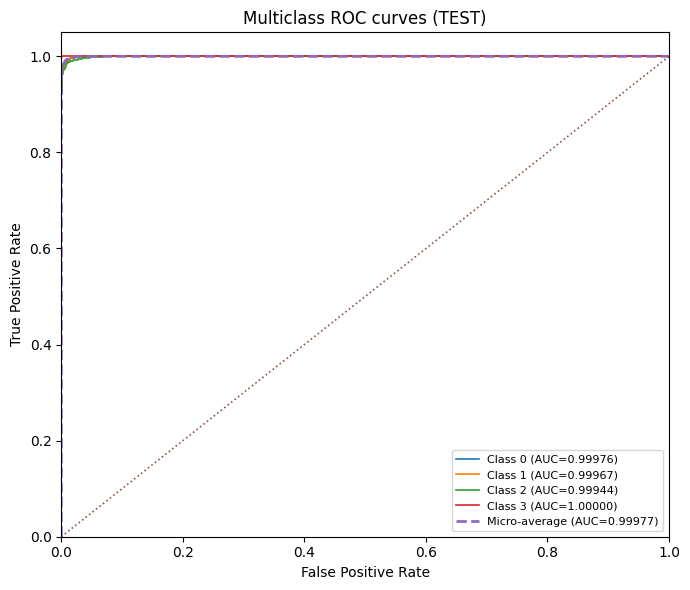

In [8]:
# ==========================================================
# Multiclass ROC & PR curves + save model as pickle
# ==========================================================
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import label_binarize
from sklearn.metrics import (
    roc_curve, auc, precision_recall_curve,
    average_precision_score, RocCurveDisplay, PrecisionRecallDisplay
)
import pickle
import os

# Use consistent class order for both binarization and predict_proba columns
class_names = np.array(sorted(np.unique(y_train)))
n_classes   = len(class_names)

# Binarize y_test to one-vs-rest
y_test_bin = label_binarize(y_test, classes=class_names)
# Predict class probabilities for TEST
y_score = best_rf.predict_proba(X_test)  # shape: (n_samples, n_classes)

# 2) ROC curves (per class, micro, macro)
fpr, tpr, roc_auc = {}, {}, {}
for i, cls in enumerate(class_names):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_score[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Micro-average ROC
fpr["micro"], tpr["micro"], _ = roc_curve(y_test_bin.ravel(), y_score.ravel())
roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])

# Macro-average ROC (mean of per-class AUCs)
roc_auc["macro"] = float(np.mean([roc_auc[i] for i in range(n_classes)]))

# --- Plot ROC ---
plt.figure(figsize=(7, 6))
# Per-class
for i, cls in enumerate(class_names):
    plt.plot(fpr[i], tpr[i], lw=1.2, label=f"Class {cls} (AUC={roc_auc[i]:.5f})")
# Micro-average
plt.plot(fpr["micro"], tpr["micro"], lw=2.0, linestyle="--", label=f"Micro-average (AUC={roc_auc['micro']:.5f})")
# Chance line
plt.plot([0, 1], [0, 1], linestyle=":", lw=1.2)
plt.xlim([0.0, 1.0]); plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Multiclass ROC curves (TEST)")
plt.legend(loc="lower right", fontsize=8)
roc_path = "roc_curves.png"
plt.tight_layout(); plt.savefig(roc_path, dpi=180); plt.show()

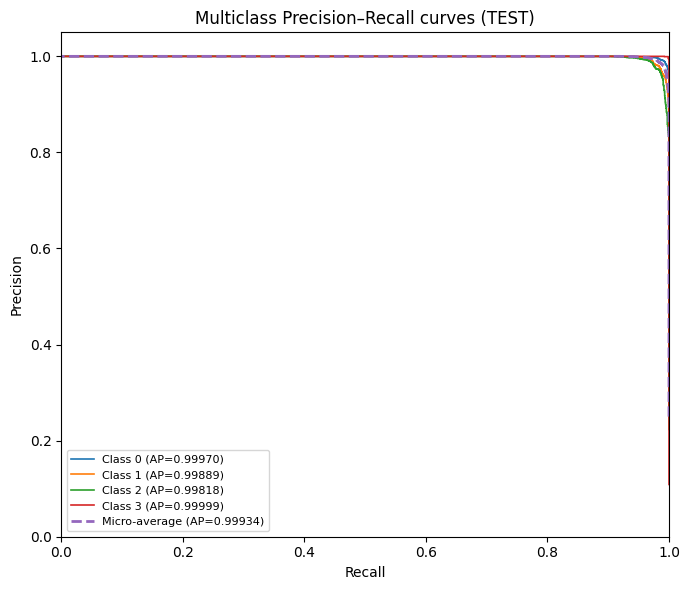

=== ROC-AUC (TEST) ===
Class 0: 0.9998
Class 1: 0.9997
Class 2: 0.9994
Class 3: 1.0000
Micro-average: 0.9998
Macro-average: 0.9997

=== PR-AUC / Average Precision (TEST) ===
Class 0: 0.9997
Class 1: 0.9989
Class 2: 0.9982
Class 3: 1.0000
Micro-average: 0.9993
Macro-average: 0.9992


In [9]:
# 3) Precision–Recall curves (per class and micro-average)
precision, recall, ap = {}, {}, {}
for i, cls in enumerate(class_names):
    precision[i], recall[i], _ = precision_recall_curve(y_test_bin[:, i], y_score[:, i])
    ap[i] = average_precision_score(y_test_bin[:, i], y_score[:, i])

# Micro-average PR
precision["micro"], recall["micro"], _ = precision_recall_curve(y_test_bin.ravel(), y_score.ravel())
ap["micro"] = average_precision_score(y_test_bin, y_score, average="micro")

# Macro-average AP (mean of per-class APs)
ap["macro"] = float(np.mean([ap[i] for i in range(n_classes)]))

# --- Plot PR ---
plt.figure(figsize=(7, 6))
for i, cls in enumerate(class_names):
    plt.plot(recall[i], precision[i], lw=1.2, label=f"Class {cls} (AP={ap[i]:.5f})")
plt.plot(recall["micro"], precision["micro"], lw=2.0, linestyle="--", label=f"Micro-average (AP={ap['micro']:.5f})")
plt.xlim([0.0, 1.0]); plt.ylim([0.0, 1.05])
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Multiclass Precision–Recall curves (TEST)")
plt.legend(loc="lower left", fontsize=8)
pr_path = "pr_curves.png"
plt.tight_layout(); plt.savefig(pr_path, dpi=180); plt.show()

# 4) Print numeric summaries
print("=== ROC-AUC (TEST) ===")
for i, cls in enumerate(class_names):
    print(f"Class {cls}: {roc_auc[i]:.4f}")
print(f"Micro-average: {roc_auc['micro']:.4f}")
print(f"Macro-average: {roc_auc['macro']:.4f}")

print("\n=== PR-AUC / Average Precision (TEST) ===")
for i, cls in enumerate(class_names):
    print(f"Class {cls}: {ap[i]:.4f}")
print(f"Micro-average: {ap['micro']:.4f}")
print(f"Macro-average: {ap['macro']:.4f}")

In [10]:
# 5) Save the tuned model as a pickle
model_path = "random_forest_best.pkl"
with open(model_path, "wb") as f:
    pickle.dump(best_rf, f)
print(f"\nSaved model to: {os.path.abspath(model_path)}")
print(f"Saved ROC figure to: {os.path.abspath(roc_path)}")
print(f"Saved PR figure to:  {os.path.abspath(pr_path)}")


Saved model to: /home/ubuntu1/projects/MPhilCodes/random_forest_best.pkl
Saved ROC figure to: /home/ubuntu1/projects/MPhilCodes/roc_curves.png
Saved PR figure to:  /home/ubuntu1/projects/MPhilCodes/pr_curves.png
